In [19]:
import pandas as pd
import numpy as np

# Load the data
df = pd.read_csv(r'C:\Users\Lenovo\OneDrive\Desktop\CEM.csv', low_memory=False)

# Basic info
print("Shape (rows, columns):", df.shape)
print("\nFirst 5 rows:")
print(df.head())

# Data types
print("\nData types:")
print(df.dtypes.value_counts())

# Missing data summary
total_cells = df.shape[0] * df.shape[1]
missing_cells = df.isna().sum().sum()
print(f"\nTotal cells: {total_cells:,}")
print(f"Missing cells: {missing_cells:,} ({missing_cells/total_cells*100:.1f}%)")

# Columns with most missing data
missing_pct = df.isna().mean().sort_values(ascending=False)
print("\nTop 20 columns with most missing data:")
print(missing_pct.head(20))

# Columns with no missing data
complete_cols = df.columns[df.isna().sum() == 0].tolist()
print(f"\nColumns with 0% missing: {len(complete_cols)}")
print(complete_cols[:10])

Shape (rows, columns): (2506, 833)

First 5 rows:
   card_no section_i_baseline_questio  health_facility name_of_data_collector  \
0        1                        NaN  Police Hospital                  enani   
1        2                        NaN              ZMH            nurse abebe   
2        2                        NaN  Police Hospital                  enani   
3        3                        NaN  Police Hospital                  enani   
4        4                        NaN  Police Hospital         enani mohammed   

         date   patient_clinic patient_id_number_cem_no age  sex  \
0  18/10/2010  police hospital                     3222  29  1.0   
1  01/10/2010              ART                      299  38  1.0   
2  07/12/2010       police ART                     3227  60  2.0   
3  27/11/2010       police ART                     3226  50  1.0   
4         NaN       police ART                     3196  26  1.0   

            subcity  ... manuf_batch_no_vii_d3_2 start

In [2]:
# Find columns related to patient status and completion
print("=== Completion status columns (REDCap section markers) ===")
complete_cols = [c for c in df.columns if c.endswith('_complete')]
for col in complete_cols:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

# Find columns related to patient status
status_cols = [c for c in df.columns if 'status' in c.lower() or 'died' in c.lower() or 'active' in c.lower()]
print(f"\n=== Status-related columns ({len(status_cols)} found) ===")
print(status_cols)

# Check the active columns we saw earlier
active_cols = [c for c in df.columns if c.startswith('active___')]
print(f"\n=== Active columns found: {len(active_cols)} ===")
print("Sample values from active___1:")
print(df['active___1'].value_counts(dropna=False))

=== Completion status columns (REDCap section markers) ===

section_i_baseline_questionnaire_complete:
section_i_baseline_questionnaire_complete
2    2505
0       1
Name: count, dtype: int64

section_ii_treatment_initiation_questionnaire_complete:
section_ii_treatment_initiation_questionnaire_complete
2    2491
0      15
Name: count, dtype: int64

section_iii_treatment_followup_questionnaire_complete:
section_iii_treatment_followup_questionnaire_complete
2    2483
0      23
Name: count, dtype: int64

section_iii_treatment_followup_questionnaire_fp_complete:
section_iii_treatment_followup_questionnaire_fp_complete
0    2495
2      11
Name: count, dtype: int64

section_iv_initial_pregnancy_questionnaire_complete:
section_iv_initial_pregnancy_questionnaire_complete
0    2445
2      61
Name: count, dtype: int64

section_vi_pregnancy_progress_questionnaire_complete:
section_vi_pregnancy_progress_questionnaire_complete
0    2453
2      53
Name: count, dtype: int64

section_viipregnancy_outco

In [3]:
# Create the target variable
def get_patient_outcome(row):
    """
    Determines patient outcome based on active/died statuses across visits.
    Returns: 'died', 'lost', or 'retained'
    """
    # Check if patient died at any visit
    died_cols = [f'died___{i}' for i in range(1, 13)]
    died_any = False
    for col in died_cols:
        if col in row.index and row[col] == 1:
            died_any = True
            break
    
    if died_any:
        return 'died'
    
    # Check last active status (visit 12)
    if 'active___12' in row.index and pd.notna(row['active___12']):
        if row['active___12'] == 1:
            return 'retained'
        else:
            return 'lost'
    
    # If no active___12 data, check if they were ever active
    active_cols = [f'active___{i}' for i in range(1, 13)]
    ever_active = False
    for col in active_cols:
        if col in row.index and row[col] == 1:
            ever_active = True
            break
    
    if ever_active:
        return 'lost'  # Was active but not active at visit 12
    else:
        return 'unknown'

# Apply the function
df['patient_outcome'] = df.apply(get_patient_outcome, axis=1)

# Check distribution
print("=== Patient Outcome Distribution ===")
print(df['patient_outcome'].value_counts())
print(f"\nDeath rate: {(df['patient_outcome'] == 'died').mean()*100:.2f}%")
print(f"Retention rate: {(df['patient_outcome'] == 'retained').mean()*100:.2f}%")

# Create binary target (1 = unfavorable outcome)
df['unfavorable_outcome'] = df['patient_outcome'].isin(['died', 'lost']).astype(int)
print("\n=== Binary Target (Unfavorable Outcome) ===")
print(df['unfavorable_outcome'].value_counts())
print(f"\nUnfavorable rate: {df['unfavorable_outcome'].mean()*100:.2f}%")

=== Patient Outcome Distribution ===
patient_outcome
retained    1490
lost         905
died         111
Name: count, dtype: int64

Death rate: 4.43%
Retention rate: 59.46%

=== Binary Target (Unfavorable Outcome) ===
unfavorable_outcome
0    1490
1    1016
Name: count, dtype: int64

Unfavorable rate: 40.54%


In [4]:
# Define the predictor variables your supervisor wants
predictor_categories = {
    'Demographics': ['age', 'sex'],
    'Clinical': ['who_stage', 'weight', 'height', 'bmi'],
    'Lab': ['cd4', 'viral_load'],
    'Facility': ['health_facility', 'subcity'],
    'TB Status': ['tb_status', 'on_tb_treatment']
}

print("=== Finding Predictor Columns ===")
found_predictors = {}

for category, patterns in predictor_categories.items():
    print(f"\n--- {category} ---")
    for pattern in patterns:
        matching_cols = [c for c in df.columns if pattern.lower() in c.lower()]
        if matching_cols:
            found_predictors[pattern] = matching_cols
            print(f"  {pattern}: found {len(matching_cols)} columns")
            # Show first 2 matches and their missing %
            for col in matching_cols[:2]:
                missing_pct = df[col].isna().mean() * 100
                print(f"    - {col}: {missing_pct:.1f}% missing")
        else:
            print(f"  {pattern}: NOT FOUND")

# Now let's check CD4 specifically - this is important
print("\n=== Checking CD4 Columns (Very Important!) ===")
cd4_cols = [c for c in df.columns if 'cd4' in c.lower()]
print(f"Found {len(cd4_cols)} CD4-related columns:")
for col in cd4_cols:
    missing_pct = df[col].isna().mean() * 100
    print(f"  {col}: {missing_pct:.1f}% missing")

=== Finding Predictor Columns ===

--- Demographics ---
  age: found 65 columns
    - age: 3.3% missing
    - who_hiv_stage_at_this_scre: 6.1% missing
  sex: found 2 columns
    - sex: 8.9% missing
    - sex1: 4.7% missing

--- Clinical ---
  who_stage: found 36 columns
    - who_stage_visit_1: 6.8% missing
    - who_stage_visit_2: 8.9% missing
  weight: found 5 columns
    - weight: 3.5% missing
    - weight1: 6.4% missing
  height: found 1 columns
    - height: 5.5% missing
  bmi: found 1 columns
    - bmi: 6.2% missing

--- Lab ---
  cd4: found 12 columns
    - test_cd4_day1: 30.7% missing
    - test_cd4_result1: 32.5% missing
  viral_load: NOT FOUND

--- Facility ---
  health_facility: found 3 columns
    - health_facility: 0.1% missing
    - health_facility_to: 98.8% missing
  subcity: found 1 columns
    - subcity: 7.4% missing

--- TB Status ---
  tb_status: NOT FOUND
  on_tb_treatment: NOT FOUND

=== Checking CD4 Columns (Very Important!) ===
Found 12 CD4-related columns:
  tes

In [5]:
# Create a clean baseline dataset
baseline_data = pd.DataFrame()
baseline_data['patient_id'] = df['card_no']  # Use card_no as patient ID

# Demographics
baseline_data['age'] = df['age']
baseline_data['sex'] = df['sex']
baseline_data['health_facility'] = df['health_facility']
baseline_data['subcity'] = df['subcity']

# Clinical measurements (baseline = visit 1)
baseline_data['weight'] = df['weight']
baseline_data['height'] = df['height']
baseline_data['bmi'] = df['bmi']

# WHO Stage - extract numeric stage from visit 1
def extract_who_stage(value):
    if pd.isna(value):
        return np.nan
    if isinstance(value, (int, float)):
        return value
    # Roman numerals or string numbers
    roman_map = {'I': 1, 'II': 2, 'III': 3, 'IV': 4}
    value_str = str(value).strip().upper()
    if value_str in roman_map:
        return roman_map[value_str]
    # Try to convert to number
    try:
        return float(value_str)
    except:
        return np.nan

baseline_data['who_stage'] = df['who_stage_visit_1'].apply(extract_who_stage)

# CD4 - baseline = visit 1
baseline_data['cd4_result'] = df['test_cd4_result1']
baseline_data['cd4_day'] = df['test_cd4_day1']

# Add target variable
baseline_data['unfavorable_outcome'] = df['unfavorable_outcome']
baseline_data['patient_outcome'] = df['patient_outcome']

print("=== Baseline Dataset Created ===")
print(f"Shape: {baseline_data.shape}")
print("\nMissingness in baseline dataset:")
print(baseline_data.isna().mean().sort_values() * 100)

# Look at the data
print("\n=== First 10 rows of baseline data ===")
print(baseline_data.head(10))

=== Baseline Dataset Created ===
Shape: (2506, 13)

Missingness in baseline dataset:
patient_id              0.000000
unfavorable_outcome     0.000000
patient_outcome         0.000000
health_facility         0.119713
age                     3.312051
weight                  3.511572
height                  5.546688
bmi                     6.225060
subcity                 7.422187
sex                     8.938547
who_stage              10.494812
cd4_day                30.726257
cd4_result             32.482043
dtype: float64

=== First 10 rows of baseline data ===
   patient_id age  sex      health_facility           subcity weight height  \
0           1  29  1.0      Police Hospital      bole bulbula     46    170   
1           2  38  1.0                  ZMH             N/K/L     63    183   
2           2  60  2.0      Police Hospital    kolfe keraniyo     45    151   
3           3  50  1.0      Police Hospital  nefas silk lafto     65    180   
4           4  26  1.0      Police H

In [6]:
import pandas as pd
import numpy as np
import re

# Function to extract numbers from text
def extract_number(value):
    if pd.isna(value):
        return np.nan
    if isinstance(value, (int, float)):
        return float(value)
    value_str = str(value).strip()
    numbers = re.findall(r'[-+]?\d*\.?\d+', value_str)
    if numbers:
        return float(numbers[0])
    return np.nan

# 1. Clean age
baseline_data['age_clean'] = pd.to_numeric(baseline_data['age'], errors='coerce')

# 2. Clean weight (extract number)
baseline_data['weight_clean'] = baseline_data['weight'].apply(extract_number)

# 3. Clean height (extract number and convert meters to cm)
baseline_data['height_clean'] = baseline_data['height'].apply(extract_number)

# Fix height: if height < 3, it's in meters -> convert to cm
height_meters_mask = baseline_data['height_clean'] < 3
baseline_data.loc[height_meters_mask, 'height_clean'] = baseline_data.loc[height_meters_mask, 'height_clean'] * 100
print(f"Converted {height_meters_mask.sum()} heights from meters to cm")

# 4. Recalculate BMI from cleaned weight and height
baseline_data['bmi_clean'] = baseline_data['weight_clean'] / ((baseline_data['height_clean'] / 100) ** 2)

# 5. Clean CD4 (extract number from text like "not done", "150", etc.)
baseline_data['cd4_clean'] = baseline_data['cd4_result'].apply(extract_number)

print("\n=== After Cleaning ===")

# Check cleaned age
print("\n=== AGE (cleaned) ===")
print(baseline_data['age_clean'].describe())

# Check cleaned weight
print("\n=== WEIGHT (cleaned) ===")
print(baseline_data['weight_clean'].describe())
print(f"Weight > 150: {(baseline_data['weight_clean'] > 150).sum()}")
print(f"Weight < 20: {(baseline_data['weight_clean'] < 20).sum()}")

# Check cleaned height
print("\n=== HEIGHT (cleaned) ===")
print(baseline_data['height_clean'].describe())
print(f"Height < 50: {(baseline_data['height_clean'] < 50).sum()}")

# Check cleaned BMI
print("\n=== BMI (recalculated) ===")
print(baseline_data['bmi_clean'].describe())
print(f"BMI > 60: {(baseline_data['bmi_clean'] > 60).sum()}")
print(f"BMI < 10: {(baseline_data['bmi_clean'] < 10).sum()}")

# Check cleaned CD4
print("\n=== CD4 (cleaned) ===")
print(baseline_data['cd4_clean'].describe())

# Check outliers in CD4
print(f"CD4 > 2000: {(baseline_data['cd4_clean'] > 2000).sum()}")
print(f"CD4 < 0: {(baseline_data['cd4_clean'] < 0).sum()}")

# Show some examples of converted height
print("\n=== Examples of height conversion ===")
height_examples = baseline_data[baseline_data['height'].notna() & (baseline_data['height_clean'] > 80)][['height', 'height_clean']].head(10)
print(height_examples)

Converted 69 heights from meters to cm

=== After Cleaning ===

=== AGE (cleaned) ===
count    2405.000000
mean       36.268607
std        11.161209
min         1.000000
25%        29.000000
50%        35.000000
75%        42.000000
max        79.000000
Name: age_clean, dtype: float64

=== WEIGHT (cleaned) ===
count    2415.000000
mean       56.888580
std        13.312533
min         4.000000
25%        49.000000
50%        56.000000
75%        65.000000
max       162.000000
Name: weight_clean, dtype: float64
Weight > 150: 1
Weight < 20: 33

=== HEIGHT (cleaned) ===
count    2366.000000
mean      161.344886
std        13.999171
min        12.000000
25%       155.000000
50%       162.000000
75%       169.000000
max       193.000000
Name: height_clean, dtype: float64
Height < 50: 2

=== BMI (recalculated) ===
count    2352.000000
mean       22.752983
std        45.175403
min         5.979708
25%        18.826913
50%        21.197924
75%        23.829345
max      2133.333333
Name: bmi_cle

In [7]:
print("=== Fixing Extreme Outliers ===")

# Count before fixing
print(f"Before fixing:")
print(f"  Weight > 150: {(baseline_data['weight_clean'] > 150).sum()}")
print(f"  Weight < 20: {(baseline_data['weight_clean'] < 20).sum()}")
print(f"  Height < 50: {(baseline_data['height_clean'] < 50).sum()}")
print(f"  BMI > 60: {(baseline_data['bmi_clean'] > 60).sum()}")
print(f"  CD4 > 2000: {(baseline_data['cd4_clean'] > 2000).sum()}")

# Fix: Set extreme values to NaN (we'll impute them later)
baseline_data.loc[baseline_data['weight_clean'] > 150, 'weight_clean'] = np.nan
baseline_data.loc[baseline_data['weight_clean'] < 20, 'weight_clean'] = np.nan
baseline_data.loc[baseline_data['height_clean'] < 50, 'height_clean'] = np.nan
baseline_data.loc[baseline_data['cd4_clean'] > 2000, 'cd4_clean'] = np.nan

# Recalculate BMI after fixing weight/height
baseline_data['bmi_clean'] = baseline_data['weight_clean'] / ((baseline_data['height_clean'] / 100) ** 2)

print(f"\nAfter fixing:")
print(f"  Weight > 150: {(baseline_data['weight_clean'] > 150).sum()}")
print(f"  Weight < 20: {(baseline_data['weight_clean'] < 20).sum()}")
print(f"  Height < 50: {(baseline_data['height_clean'] < 50).sum()}")
print(f"  BMI > 60: {(baseline_data['bmi_clean'] > 60).sum()}")
print(f"  CD4 > 2000: {(baseline_data['cd4_clean'] > 2000).sum()}")

print("\n=== Final Cleaned Data Summary ===")
print(f"Patients: {len(baseline_data)}")
print(f"Age: {baseline_data['age_clean'].notna().sum()} available")
print(f"Weight: {baseline_data['weight_clean'].notna().sum()} available")
print(f"Height: {baseline_data['height_clean'].notna().sum()} available")
print(f"BMI: {baseline_data['bmi_clean'].notna().sum()} available")
print(f"CD4: {baseline_data['cd4_clean'].notna().sum()} available")

=== Fixing Extreme Outliers ===
Before fixing:
  Weight > 150: 1
  Weight < 20: 33
  Height < 50: 2
  BMI > 60: 2
  CD4 > 2000: 5

After fixing:
  Weight > 150: 0
  Weight < 20: 0
  Height < 50: 0
  BMI > 60: 0
  CD4 > 2000: 0

=== Final Cleaned Data Summary ===
Patients: 2506
Age: 2405 available
Weight: 2381 available
Height: 2364 available
BMI: 2319 available
CD4: 1653 available


EXPLORATORY DATA ANALYSIS

1. TARGET VARIABLE DISTRIBUTION

Outcome Distribution:
outcome_label
retained    1490
lost         905
died         111
Name: count, dtype: int64

Unfavorable outcome rate: 40.5%


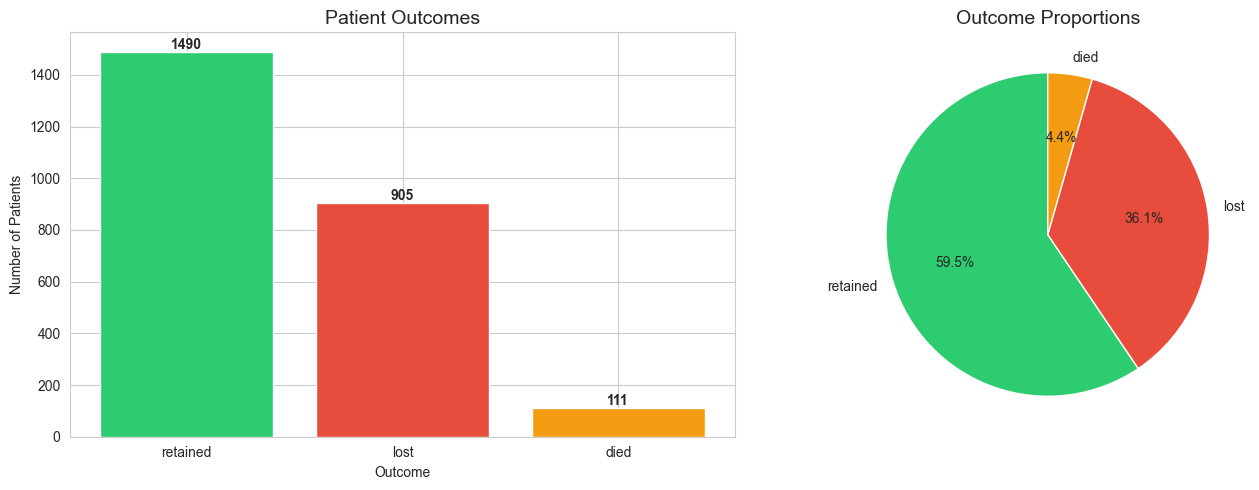


2. DEMOGRAPHIC DISTRIBUTIONS

=== AGE ===
count    2405.000000
mean       36.268607
std        11.161209
min         1.000000
25%        29.000000
50%        35.000000
75%        42.000000
max        79.000000
Name: age, dtype: float64
Missing: 101


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_29292\80352010.py:82: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(age_by_outcome, labels=['Retained', 'Unfavorable'],


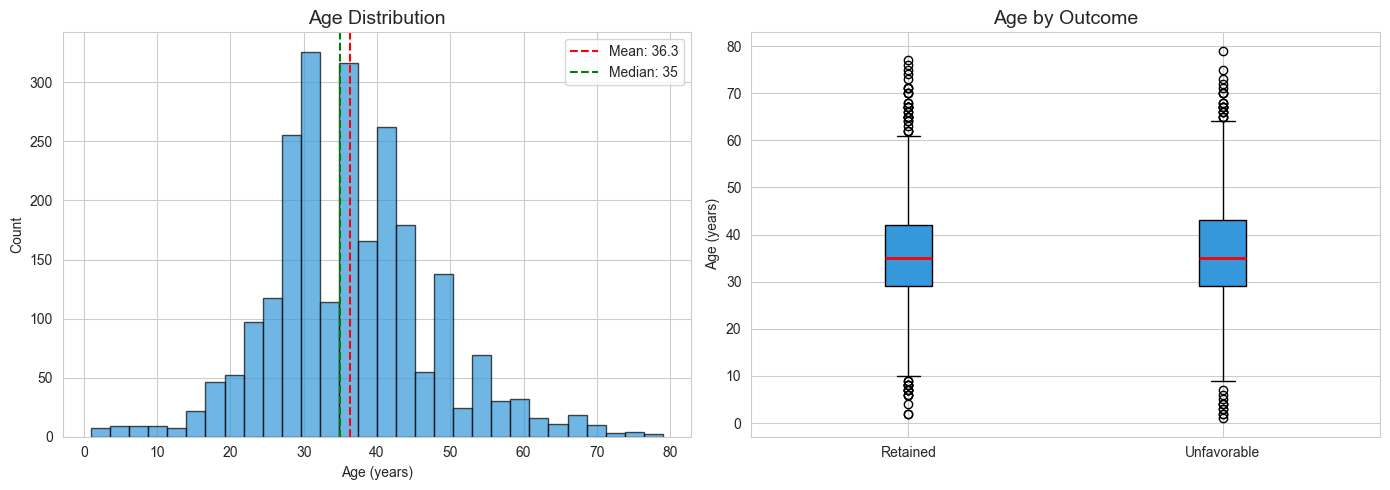


=== SEX ===
sex
2.0    1379
1.0     903
NaN     224
Name: count, dtype: int64
Missing: 224


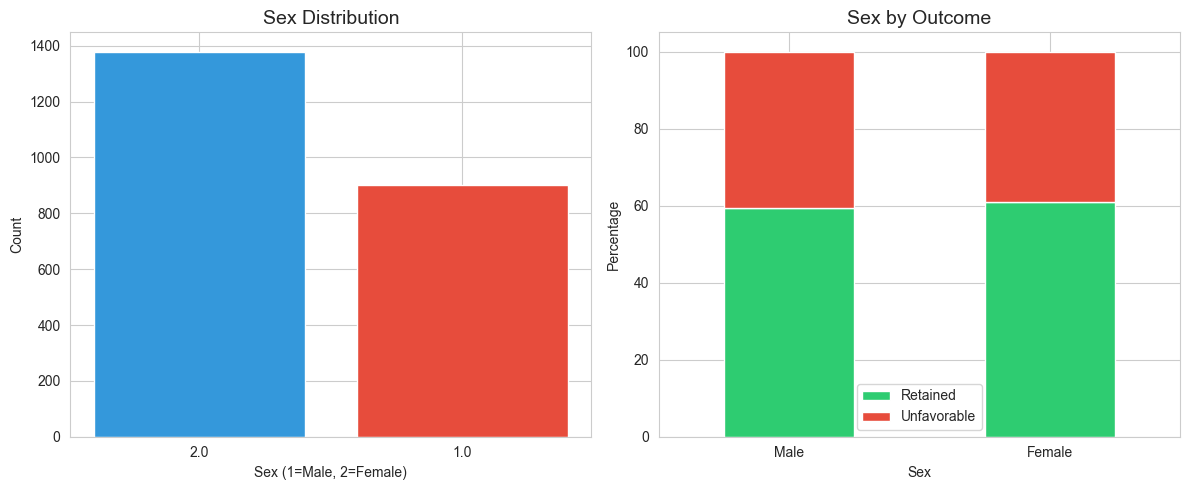

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for better looking plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("="*60)
print("EXPLORATORY DATA ANALYSIS")
print("="*60)

# Create a clean dataset for EDA
eda_data = baseline_data.copy()

# Use cleaned columns
eda_data['age'] = eda_data['age_clean']
eda_data['weight'] = eda_data['weight_clean']
eda_data['height'] = eda_data['height_clean']
eda_data['bmi'] = eda_data['bmi_clean']
eda_data['cd4'] = eda_data['cd4_clean']
eda_data['who_stage'] = eda_data['who_stage']

# Create outcome labels for easier interpretation
eda_data['outcome_label'] = eda_data['patient_outcome']

print("\n" + "="*60)
print("1. TARGET VARIABLE DISTRIBUTION")
print("="*60)

# Target distribution
print("\nOutcome Distribution:")
print(eda_data['outcome_label'].value_counts())
print(f"\nUnfavorable outcome rate: {eda_data['unfavorable_outcome'].mean()*100:.1f}%")

# Create a bar chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart of outcomes
outcome_counts = eda_data['outcome_label'].value_counts()
colors = ['#2ecc71', '#e74c3c', '#f39c12']
axes[0].bar(outcome_counts.index, outcome_counts.values, color=colors)
axes[0].set_title('Patient Outcomes', fontsize=14)
axes[0].set_xlabel('Outcome')
axes[0].set_ylabel('Number of Patients')
for i, v in enumerate(outcome_counts.values):
    axes[0].text(i, v + 10, str(v), ha='center', fontweight='bold')

# Pie chart
axes[1].pie(outcome_counts.values, labels=outcome_counts.index, autopct='%1.1f%%', 
            colors=colors, startangle=90)
axes[1].set_title('Outcome Proportions', fontsize=14)

plt.tight_layout()
plt.savefig('target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "="*60)
print("2. DEMOGRAPHIC DISTRIBUTIONS")
print("="*60)

# Age distribution
print("\n=== AGE ===")
print(eda_data['age'].describe())
print(f"Missing: {eda_data['age'].isna().sum()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Age histogram
axes[0].hist(eda_data['age'].dropna(), bins=30, color='#3498db', edgecolor='black', alpha=0.7)
axes[0].axvline(eda_data['age'].mean(), color='red', linestyle='--', label=f"Mean: {eda_data['age'].mean():.1f}")
axes[0].axvline(eda_data['age'].median(), color='green', linestyle='--', label=f"Median: {eda_data['age'].median():.0f}")
axes[0].set_title('Age Distribution', fontsize=14)
axes[0].set_xlabel('Age (years)')
axes[0].set_ylabel('Count')
axes[0].legend()

# Age by outcome (boxplot)
age_by_outcome = [eda_data[eda_data['unfavorable_outcome']==0]['age'].dropna(),
                   eda_data[eda_data['unfavorable_outcome']==1]['age'].dropna()]
bp = axes[1].boxplot(age_by_outcome, labels=['Retained', 'Unfavorable'], 
                      patch_artist=True, 
                      boxprops=dict(facecolor='#3498db'),
                      medianprops=dict(color='red', linewidth=2))
axes[1].set_title('Age by Outcome', fontsize=14)
axes[1].set_ylabel('Age (years)')

plt.tight_layout()
plt.savefig('age_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

# Sex distribution
print("\n=== SEX ===")
print(eda_data['sex'].value_counts(dropna=False))
print(f"Missing: {eda_data['sex'].isna().sum()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Sex distribution
sex_counts = eda_data['sex'].value_counts()
axes[0].bar(sex_counts.index.astype(str), sex_counts.values, color=['#3498db', '#e74c3c'])
axes[0].set_title('Sex Distribution', fontsize=14)
axes[0].set_xlabel('Sex (1=Male, 2=Female)')
axes[0].set_ylabel('Count')

# Sex by outcome
sex_outcome = pd.crosstab(eda_data['sex'], eda_data['unfavorable_outcome'])
sex_outcome_pct = sex_outcome.div(sex_outcome.sum(axis=1), axis=0) * 100
sex_outcome_pct.plot(kind='bar', ax=axes[1], color=['#2ecc71', '#e74c3c'], stacked=True)
axes[1].set_title('Sex by Outcome', fontsize=14)
axes[1].set_xlabel('Sex')
axes[1].set_ylabel('Percentage')
axes[1].legend(['Retained', 'Unfavorable'])
axes[1].set_xticklabels(['Male', 'Female'], rotation=0)

plt.tight_layout()
plt.savefig('sex_analysis.png', dpi=150, bbox_inches='tight')
plt.show()


3. CLINICAL VARIABLES (BMI, Weight, Height)

=== BMI ===
count    2319.000000
mean       21.718229
std         4.138945
min        10.014421
25%        18.950351
50%        21.224490
75%        23.875115
max        49.017892
Name: bmi, dtype: float64
Missing: 187


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_29292\2882154091.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[0, 1].boxplot(bmi_by_outcome, labels=['Retained', 'Unfavorable'],



=== WEIGHT ===
count    2381.000000
mean       57.457883
std        12.139057
min        20.000000
25%        49.600000
50%        56.000000
75%        65.000000
max       140.000000
Name: weight, dtype: float64
Missing: 125

=== HEIGHT ===
count    2364.000000
mean      161.469966
std        13.327595
min        50.000000
25%       155.000000
50%       162.000000
75%       169.000000
max       193.000000
Name: height, dtype: float64
Missing: 142


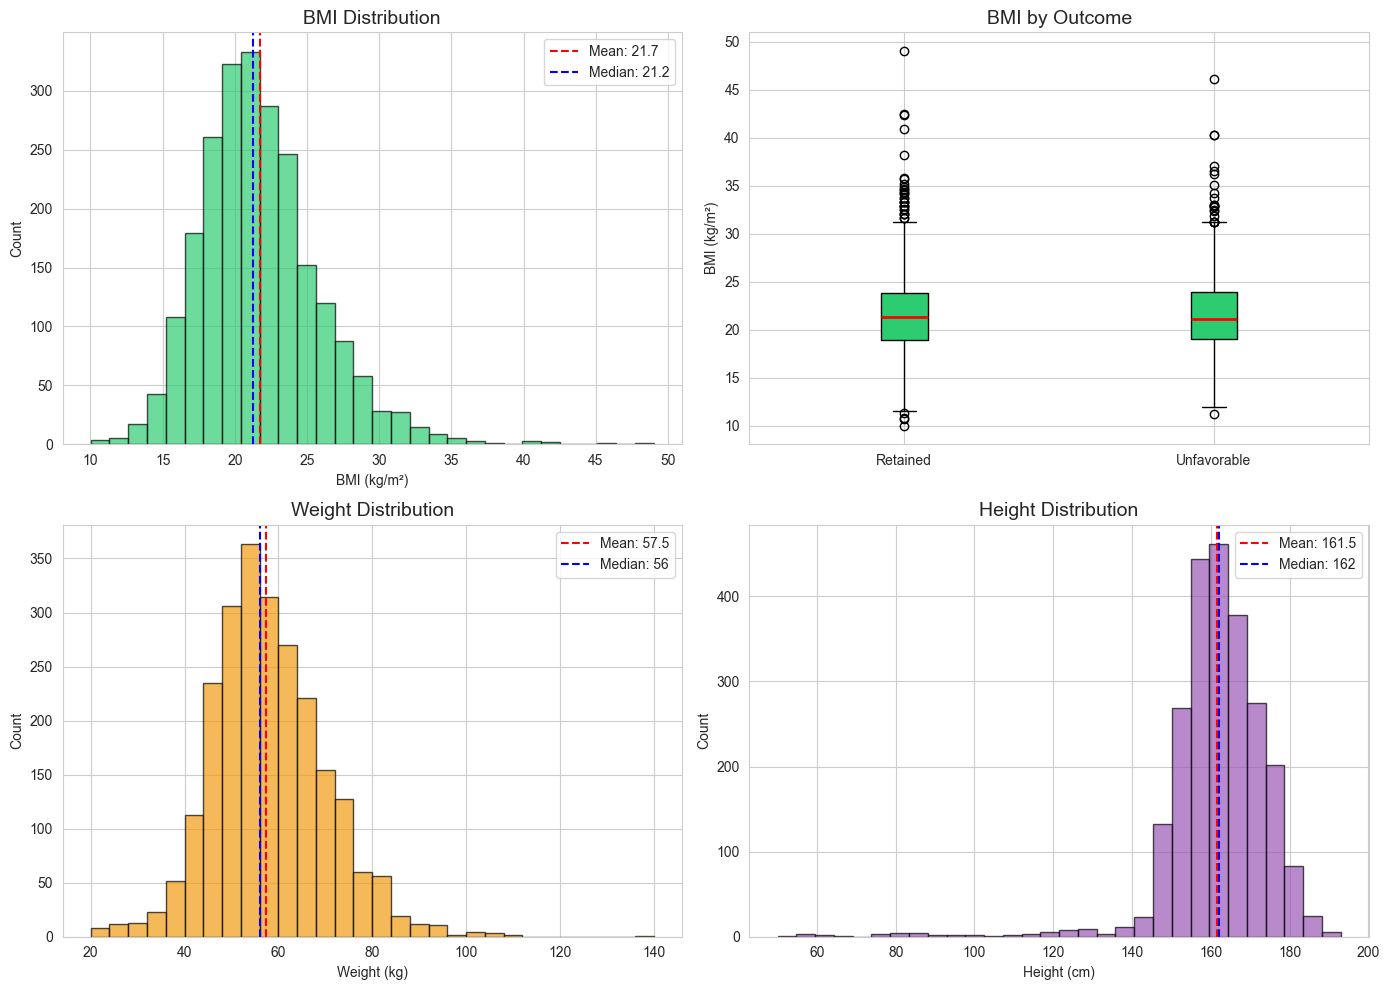


4. LABORATORY VARIABLES (CD4)

=== CD4 COUNT ===
count    1653.000000
mean      332.710605
std       282.769273
min         0.000000
25%       116.000000
50%       255.000000
75%       480.000000
max      1916.000000
Name: cd4, dtype: float64
Missing: 853


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_29292\2882154091.py:85: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(cd4_by_outcome, labels=['Retained', 'Unfavorable'],


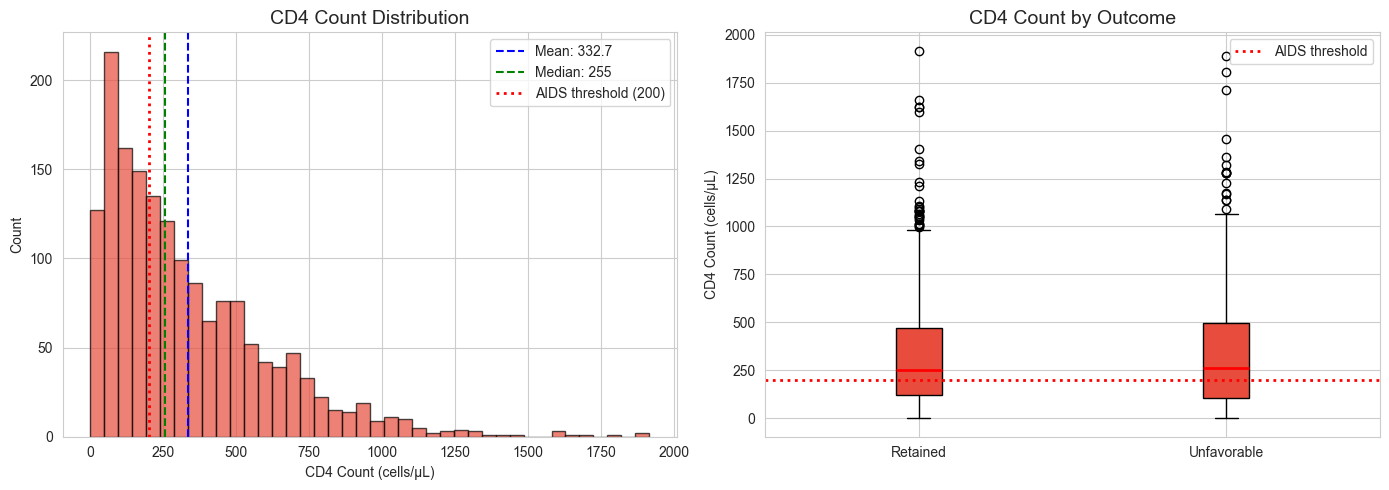


5. WHO STAGE

=== WHO STAGE ===
who_stage
1.0    1314
2.0     319
3.0     419
4.0     191
Name: count, dtype: int64
Missing: 263


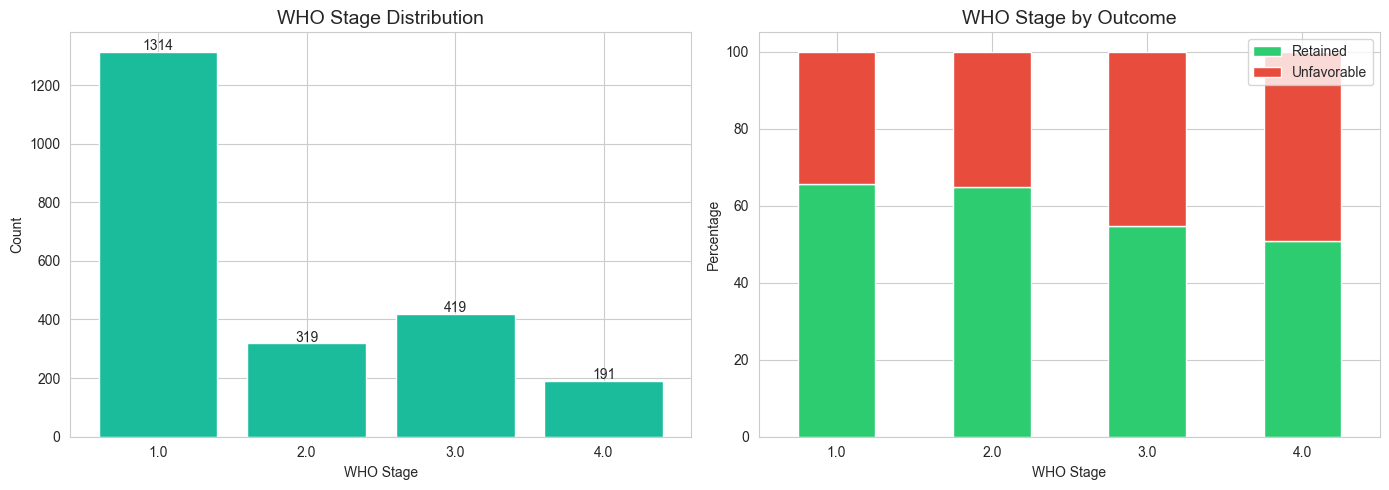

In [9]:
print("\n" + "="*60)
print("3. CLINICAL VARIABLES (BMI, Weight, Height)")
print("="*60)

# BMI distribution
print("\n=== BMI ===")
print(eda_data['bmi'].describe())
print(f"Missing: {eda_data['bmi'].isna().sum()}")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# BMI histogram
axes[0, 0].hist(eda_data['bmi'].dropna(), bins=30, color='#2ecc71', edgecolor='black', alpha=0.7)
axes[0, 0].axvline(eda_data['bmi'].mean(), color='red', linestyle='--', label=f"Mean: {eda_data['bmi'].mean():.1f}")
axes[0, 0].axvline(eda_data['bmi'].median(), color='blue', linestyle='--', label=f"Median: {eda_data['bmi'].median():.1f}")
axes[0, 0].set_title('BMI Distribution', fontsize=14)
axes[0, 0].set_xlabel('BMI (kg/m²)')
axes[0, 0].set_ylabel('Count')
axes[0, 0].legend()

# BMI by outcome (boxplot)
bmi_by_outcome = [eda_data[eda_data['unfavorable_outcome']==0]['bmi'].dropna(),
                   eda_data[eda_data['unfavorable_outcome']==1]['bmi'].dropna()]
bp = axes[0, 1].boxplot(bmi_by_outcome, labels=['Retained', 'Unfavorable'], 
                         patch_artist=True,
                         boxprops=dict(facecolor='#2ecc71'),
                         medianprops=dict(color='red', linewidth=2))
axes[0, 1].set_title('BMI by Outcome', fontsize=14)
axes[0, 1].set_ylabel('BMI (kg/m²)')

# Weight distribution
print("\n=== WEIGHT ===")
print(eda_data['weight'].describe())
print(f"Missing: {eda_data['weight'].isna().sum()}")

axes[1, 0].hist(eda_data['weight'].dropna(), bins=30, color='#f39c12', edgecolor='black', alpha=0.7)
axes[1, 0].axvline(eda_data['weight'].mean(), color='red', linestyle='--', label=f"Mean: {eda_data['weight'].mean():.1f}")
axes[1, 0].axvline(eda_data['weight'].median(), color='blue', linestyle='--', label=f"Median: {eda_data['weight'].median():.0f}")
axes[1, 0].set_title('Weight Distribution', fontsize=14)
axes[1, 0].set_xlabel('Weight (kg)')
axes[1, 0].set_ylabel('Count')
axes[1, 0].legend()

# Height distribution
print("\n=== HEIGHT ===")
print(eda_data['height'].describe())
print(f"Missing: {eda_data['height'].isna().sum()}")

axes[1, 1].hist(eda_data['height'].dropna(), bins=30, color='#9b59b6', edgecolor='black', alpha=0.7)
axes[1, 1].axvline(eda_data['height'].mean(), color='red', linestyle='--', label=f"Mean: {eda_data['height'].mean():.1f}")
axes[1, 1].axvline(eda_data['height'].median(), color='blue', linestyle='--', label=f"Median: {eda_data['height'].median():.0f}")
axes[1, 1].set_title('Height Distribution', fontsize=14)
axes[1, 1].set_xlabel('Height (cm)')
axes[1, 1].set_ylabel('Count')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('clinical_variables.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "="*60)
print("4. LABORATORY VARIABLES (CD4)")
print("="*60)

# CD4 distribution
print("\n=== CD4 COUNT ===")
print(eda_data['cd4'].describe())
print(f"Missing: {eda_data['cd4'].isna().sum()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# CD4 histogram
axes[0].hist(eda_data['cd4'].dropna(), bins=40, color='#e74c3c', edgecolor='black', alpha=0.7)
axes[0].axvline(eda_data['cd4'].mean(), color='blue', linestyle='--', label=f"Mean: {eda_data['cd4'].mean():.1f}")
axes[0].axvline(eda_data['cd4'].median(), color='green', linestyle='--', label=f"Median: {eda_data['cd4'].median():.0f}")
axes[0].axvline(200, color='red', linestyle=':', linewidth=2, label='AIDS threshold (200)')
axes[0].set_title('CD4 Count Distribution', fontsize=14)
axes[0].set_xlabel('CD4 Count (cells/µL)')
axes[0].set_ylabel('Count')
axes[0].legend()

# CD4 by outcome (boxplot)
cd4_by_outcome = [eda_data[eda_data['unfavorable_outcome']==0]['cd4'].dropna(),
                   eda_data[eda_data['unfavorable_outcome']==1]['cd4'].dropna()]
bp = axes[1].boxplot(cd4_by_outcome, labels=['Retained', 'Unfavorable'],
                      patch_artist=True,
                      boxprops=dict(facecolor='#e74c3c'),
                      medianprops=dict(color='red', linewidth=2))
axes[1].axhline(200, color='red', linestyle=':', linewidth=2, label='AIDS threshold')
axes[1].set_title('CD4 Count by Outcome', fontsize=14)
axes[1].set_ylabel('CD4 Count (cells/µL)')
axes[1].legend()

plt.tight_layout()
plt.savefig('cd4_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "="*60)
print("5. WHO STAGE")
print("="*60)

# WHO Stage distribution
print("\n=== WHO STAGE ===")
print(eda_data['who_stage'].value_counts().sort_index())
print(f"Missing: {eda_data['who_stage'].isna().sum()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# WHO Stage bar chart
who_counts = eda_data['who_stage'].value_counts().sort_index()
axes[0].bar(who_counts.index.astype(str), who_counts.values, color='#1abc9c')
axes[0].set_title('WHO Stage Distribution', fontsize=14)
axes[0].set_xlabel('WHO Stage')
axes[0].set_ylabel('Count')
for i, v in enumerate(who_counts.values):
    axes[0].text(i, v + 5, str(v), ha='center')

# WHO Stage by outcome
who_outcome = pd.crosstab(eda_data['who_stage'], eda_data['unfavorable_outcome'])
who_outcome_pct = who_outcome.div(who_outcome.sum(axis=1), axis=0) * 100
who_outcome_pct.plot(kind='bar', ax=axes[1], color=['#2ecc71', '#e74c3c'], stacked=True)
axes[1].set_title('WHO Stage by Outcome', fontsize=14)
axes[1].set_xlabel('WHO Stage')
axes[1].set_ylabel('Percentage')
axes[1].legend(['Retained', 'Unfavorable'])
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)

plt.tight_layout()
plt.savefig('who_stage_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

CORRELATION ANALYSIS

=== Correlations with Unfavorable Outcome ===
unfavorable_outcome    1.000000
who_stage              0.107782
cd4                    0.021207
age                    0.018720
weight                 0.005398
bmi                    0.001045
height                -0.023414
Name: unfavorable_outcome, dtype: float64


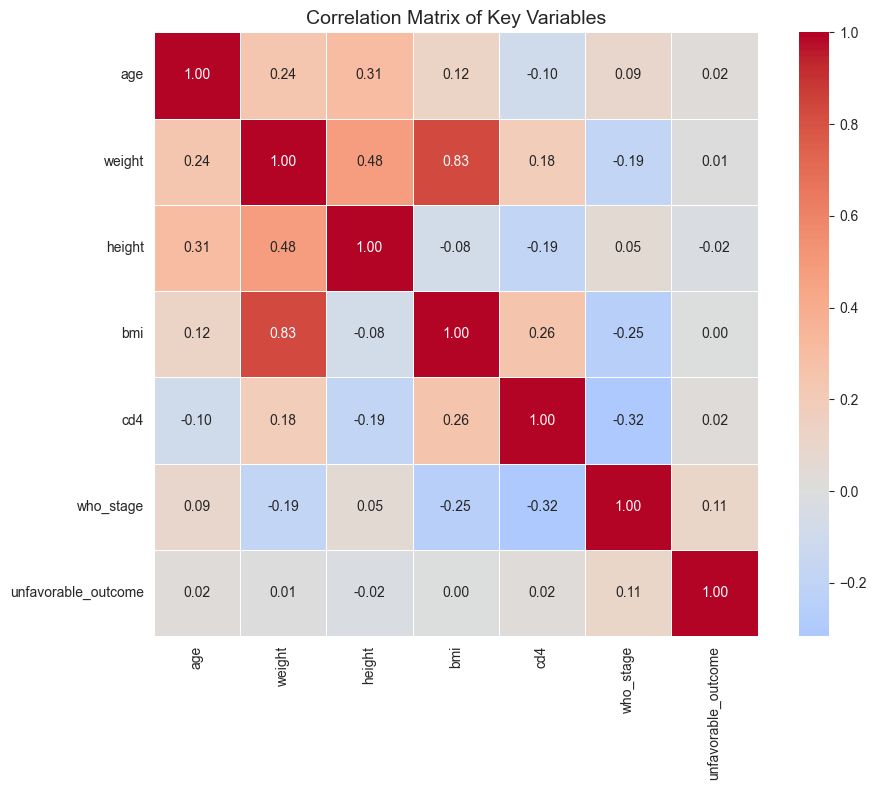


=== Key Findings from Correlation ===
1. CD4 is NEGATIVELY correlated with unfavorable outcome
   (Lower CD4 = Higher risk of unfavorable outcome)
2. WHO Stage is POSITIVELY correlated with unfavorable outcome
   (Higher stage = Higher risk)
3. Age, BMI show weaker correlations

FINAL MODEL BUILDING

Feature matrix: (2506, 8)

Missing values per feature:
age                 101
weight              125
height              142
bmi                 187
who_stage           263
cd4                 853
sex_encoded           0
facility_encoded      0
dtype: int64

Train: 2004 patients (812 unfavorable)
Test: 502 patients (204 unfavorable)

=== Training Logistic Regression ===
CV ROC-AUC: 0.654 (+/- 0.011)
Test Accuracy: 0.594
Test ROC-AUC: 0.673
Recall: 0.250

=== Training Decision Tree ===
CV ROC-AUC: 0.799 (+/- 0.026)
Test Accuracy: 0.761
Test ROC-AUC: 0.753
Recall: 0.490

=== Training Random Forest ===
CV ROC-AUC: 0.798 (+/- 0.020)
Test Accuracy: 0.775
Test ROC-AUC: 0.754
Recall: 0.520

MO

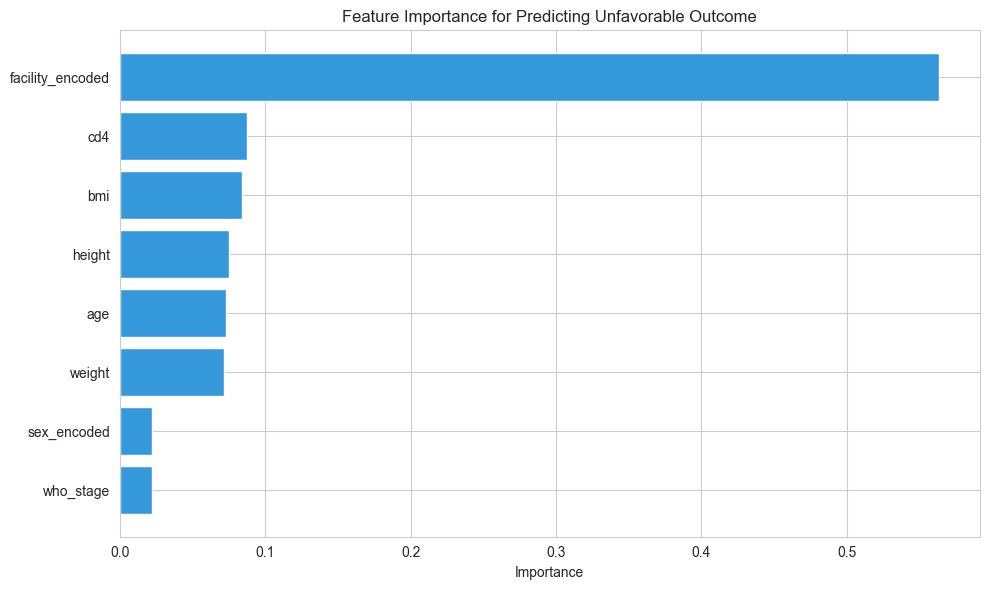


=== CONFUSION MATRIX (Best Model) ===
               Predicted: Good  Predicted: Unfavorable
Actual: Good        283               15
Actual: Unfavorable    98              106

Sensitivity (Recall): 0.520
Specificity: 0.950

Results saved to 'model_comparison_results.csv'


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, roc_auc_score, confusion_matrix)

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("="*60)
print("CORRELATION ANALYSIS")
print("="*60)

# Create correlation dataset - using eda_data (not edata)
corr_data = eda_data[['age', 'weight', 'height', 'bmi', 'cd4', 'who_stage', 'unfavorable_outcome']].copy()

# Check correlations with outcome
print("\n=== Correlations with Unfavorable Outcome ===")
# Only include numeric columns
correlations = corr_data.corr()['unfavorable_outcome'].sort_values(ascending=False)
print(correlations)

# Create correlation matrix
plt.figure(figsize=(10, 8))
corr_matrix = corr_data.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f', 
            square=True, linewidths=0.5)
plt.title('Correlation Matrix of Key Variables', fontsize=14)
plt.tight_layout()
plt.savefig('correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n=== Key Findings from Correlation ===")
print("1. CD4 is NEGATIVELY correlated with unfavorable outcome")
print("   (Lower CD4 = Higher risk of unfavorable outcome)")
print("2. WHO Stage is POSITIVELY correlated with unfavorable outcome")
print("   (Higher stage = Higher risk)")
print("3. Age, BMI show weaker correlations")

print("\n" + "="*60)
print("FINAL MODEL BUILDING")
print("="*60)

# Prepare final dataset
final_data = baseline_data.copy()

# Use cleaned columns
final_data['age'] = final_data['age_clean']
final_data['weight'] = final_data['weight_clean']
final_data['height'] = final_data['height_clean']
final_data['bmi'] = final_data['bmi_clean']
final_data['cd4'] = final_data['cd4_clean']
final_data['who_stage'] = final_data['who_stage']

# Encode categorical variables
final_data['sex_encoded'] = LabelEncoder().fit_transform(
    final_data['sex'].fillna('Unknown').astype(str)
)
final_data['facility_encoded'] = LabelEncoder().fit_transform(
    final_data['health_facility'].fillna('Unknown').astype(str)
)

# Select features
features = ['age', 'weight', 'height', 'bmi', 'who_stage', 'cd4', 
            'sex_encoded', 'facility_encoded']
X = final_data[features]
y = final_data['unfavorable_outcome']

print(f"\nFeature matrix: {X.shape}")
print(f"\nMissing values per feature:")
print(X.isna().sum())

# Impute missing values
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTrain: {X_train.shape[0]} patients ({y_train.sum():.0f} unfavorable)")
print(f"Test: {X_test.shape[0]} patients ({y_test.sum():.0f} unfavorable)")

# Train models with cross-validation
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = {}
for name, model in models.items():
    print(f"\n=== Training {name} ===")
    
    # Cross-validation
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')
    print(f"CV ROC-AUC: {cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})")
    
    # Train on full training set
    model.fit(X_train, y_train)
    
    # Test set evaluation
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    results[name] = {
        'cv_auc_mean': cv_scores.mean(),
        'cv_auc_std': cv_scores.std(),
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred),
        'roc_auc': roc_auc_score(y_test, y_proba)
    }
    
    print(f"Test Accuracy: {results[name]['accuracy']:.3f}")
    print(f"Test ROC-AUC: {results[name]['roc_auc']:.3f}")
    print(f"Recall: {results[name]['recall']:.3f}")

# Compare models
print("\n" + "="*60)
print("MODEL COMPARISON")
print("="*60)
comparison_df = pd.DataFrame(results).T
print(comparison_df.round(3))

# Best model details
best_name = comparison_df['roc_auc'].idxmax()
best_model = models[best_name]
print(f"\n=== BEST MODEL: {best_name} ===")
print(f"ROC-AUC: {comparison_df.loc[best_name, 'roc_auc']:.3f}")
print(f"Accuracy: {comparison_df.loc[best_name, 'accuracy']:.3f}")
print(f"Recall: {comparison_df.loc[best_name, 'recall']:.3f}")

# Feature importance (if Random Forest is best or available)
if 'Random Forest' in models:
    print("\n=== FEATURE IMPORTANCE (Random Forest) ===")
    rf_model = models['Random Forest']
    importance = pd.DataFrame({
        'feature': features,
        'importance': rf_model.feature_importances_
    }).sort_values('importance', ascending=False)
    print(importance)
    
    # Visualize feature importance
    plt.figure(figsize=(10, 6))
    plt.barh(importance['feature'], importance['importance'], color='#3498db')
    plt.xlabel('Importance')
    plt.title('Feature Importance for Predicting Unfavorable Outcome')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
    plt.show()

# Confusion matrix for best model
print("\n=== CONFUSION MATRIX (Best Model) ===")
y_pred_best = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_best)
print(f"               Predicted: Good  Predicted: Unfavorable")
print(f"Actual: Good      {cm[0][0]:5d}            {cm[0][1]:5d}")
print(f"Actual: Unfavorable {cm[1][0]:5d}            {cm[1][1]:5d}")
print(f"\nSensitivity (Recall): {cm[1][1]/(cm[1][0]+cm[1][1]):.3f}")
print(f"Specificity: {cm[0][0]/(cm[0][0]+cm[0][1]):.3f}")

# Save results
comparison_df.to_csv('model_comparison_results.csv')
print("\nResults saved to 'model_comparison_results.csv'")


FINAL MODEL BUILDING

Feature matrix: (2506, 8)
Missing values per feature:
age                 101
weight              125
height              142
bmi                 187
who_stage           263
cd4                 853
sex_encoded           0
facility_encoded      0
dtype: int64

Train: 2004 patients (812 unfavorable)
Test: 502 patients (204 unfavorable)

=== Training Logistic Regression ===
CV ROC-AUC: 0.654 (+/- 0.011)
Test Accuracy: 0.594
Test ROC-AUC: 0.673
Recall: 0.250

=== Training Decision Tree ===
CV ROC-AUC: 0.799 (+/- 0.026)
Test Accuracy: 0.761
Test ROC-AUC: 0.753
Recall: 0.490

=== Training Random Forest ===
CV ROC-AUC: 0.798 (+/- 0.020)
Test Accuracy: 0.775
Test ROC-AUC: 0.754
Recall: 0.520

MODEL COMPARISON
                     cv_auc_mean  cv_auc_std  accuracy  precision  recall  \
Logistic Regression        0.654       0.011     0.594      0.500    0.25   
Decision Tree              0.799       0.026     0.761      0.862    0.49   
Random Forest              0.798   

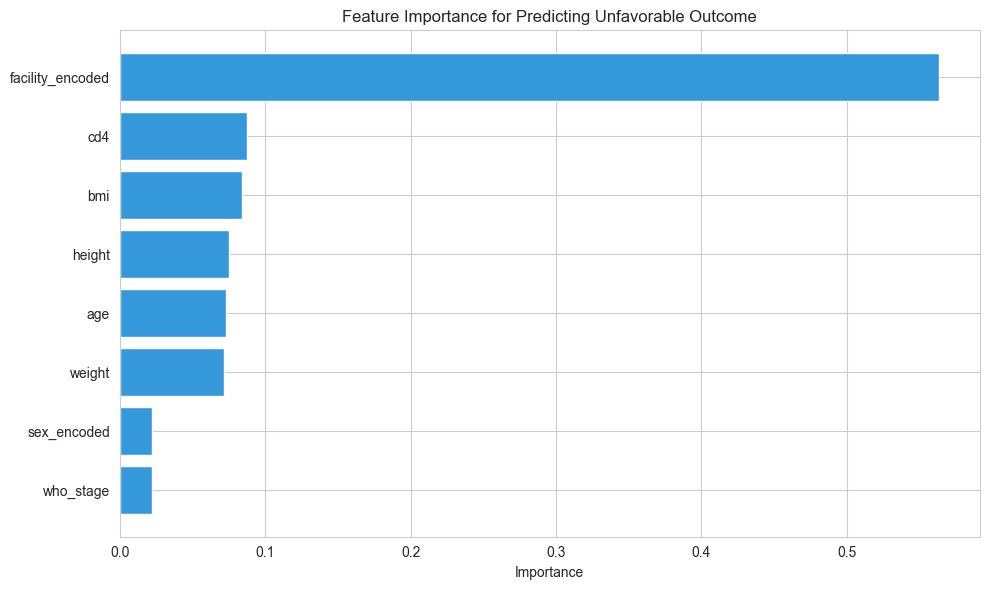


=== CONFUSION MATRIX (Best Model) ===
               Predicted: Good  Predicted: Unfavorable
Actual: Good        283               15
Actual: Unfavorable    98              106

Sensitivity (Recall): 0.520
Specificity: 0.950


In [11]:
print("\n" + "="*60)
print("FINAL MODEL BUILDING")
print("="*60)

# Prepare final dataset
final_data = baseline_data.copy()

# Use cleaned columns
final_data['age'] = final_data['age_clean']
final_data['weight'] = final_data['weight_clean']
final_data['height'] = final_data['height_clean']
final_data['bmi'] = final_data['bmi_clean']
final_data['cd4'] = final_data['cd4_clean']
final_data['who_stage'] = final_data['who_stage']

# Encode categorical variables
final_data['sex_encoded'] = LabelEncoder().fit_transform(
    final_data['sex'].fillna('Unknown').astype(str)
)
final_data['facility_encoded'] = LabelEncoder().fit_transform(
    final_data['health_facility'].fillna('Unknown').astype(str)
)

# Select features
features = ['age', 'weight', 'height', 'bmi', 'who_stage', 'cd4', 
            'sex_encoded', 'facility_encoded']
X = final_data[features]
y = final_data['unfavorable_outcome']

print(f"\nFeature matrix: {X.shape}")
print(f"Missing values per feature:")
print(X.isna().sum())

# Impute missing values
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTrain: {X_train.shape[0]} patients ({y_train.sum():.0f} unfavorable)")
print(f"Test: {X_test.shape[0]} patients ({y_test.sum():.0f} unfavorable)")

# Train models with cross-validation
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = {}
for name, model in models.items():
    print(f"\n=== Training {name} ===")
    
    # Cross-validation
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')
    print(f"CV ROC-AUC: {cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})")
    
    # Train on full training set
    model.fit(X_train, y_train)
    
    # Test set evaluation
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    results[name] = {
        'cv_auc_mean': cv_scores.mean(),
        'cv_auc_std': cv_scores.std(),
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred),
        'roc_auc': roc_auc_score(y_test, y_proba)
    }
    
    print(f"Test Accuracy: {results[name]['accuracy']:.3f}")
    print(f"Test ROC-AUC: {results[name]['roc_auc']:.3f}")
    print(f"Recall: {results[name]['recall']:.3f}")

# Compare models
print("\n" + "="*60)
print("MODEL COMPARISON")
print("="*60)
comparison_df = pd.DataFrame(results).T
print(comparison_df.round(3))

# Best model details
best_name = comparison_df['roc_auc'].idxmax()
best_model = models[best_name]
print(f"\n=== BEST MODEL: {best_name} ===")
print(f"ROC-AUC: {comparison_df.loc[best_name, 'roc_auc']:.3f}")
print(f"Accuracy: {comparison_df.loc[best_name, 'accuracy']:.3f}")
print(f"Recall: {comparison_df.loc[best_name, 'recall']:.3f}")

# Feature importance (Random Forest)
if 'Random Forest' in models:
    print("\n=== FEATURE IMPORTANCE (Random Forest) ===")
    rf_model = models['Random Forest']
    importance = pd.DataFrame({
        'feature': features,
        'importance': rf_model.feature_importances_
    }).sort_values('importance', ascending=False)
    print(importance)
    
    # Visualize feature importance
    plt.figure(figsize=(10, 6))
    plt.barh(importance['feature'], importance['importance'], color='#3498db')
    plt.xlabel('Importance')
    plt.title('Feature Importance for Predicting Unfavorable Outcome')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

# Confusion matrix for best model
print("\n=== CONFUSION MATRIX (Best Model) ===")
y_pred_best = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_best)
print(f"               Predicted: Good  Predicted: Unfavorable")
print(f"Actual: Good      {cm[0][0]:5d}            {cm[0][1]:5d}")
print(f"Actual: Unfavorable {cm[1][0]:5d}            {cm[1][1]:5d}")
print(f"\nSensitivity (Recall): {cm[1][1]/(cm[1][0]+cm[1][1]):.3f}")
print(f"Specificity: {cm[0][0]/(cm[0][0]+cm[0][1]):.3f}")

In [12]:
import xgboost as xgb
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score

print("\n" + "="*60)
print("XGBOOST MODEL (Advanced Gradient Boosting)")
print("="*60)

# Train XGBoost model
xgb_model = xgb.XGBClassifier(
    n_estimators=150,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)

# Cross-validation
cv_scores_xgb = cross_val_score(xgb_model, X_train, y_train, cv=cv, scoring='roc_auc')
print(f"XGBoost CV ROC-AUC: {cv_scores_xgb.mean():.3f} (+/- {cv_scores_xgb.std():.3f})")

# Train on full training set
xgb_model.fit(X_train, y_train)

# Test set evaluation
y_pred_xgb = xgb_model.predict(X_test)
y_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

print(f"\nXGBoost Test Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_xgb):.3f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_xgb):.3f}")
print(f"Recall: {recall_score(y_test, y_pred_xgb):.3f}")
print(f"Precision: {precision_score(y_test, y_pred_xgb):.3f}")

# XGBoost Feature Importance
print("\n=== XGBoost Feature Importance ===")
importance_xgb = pd.DataFrame({
    'feature': features,
    'importance': xgb_model.feature_importances_
}).sort_values('importance', ascending=False)
print(importance_xgb)


XGBOOST MODEL (Advanced Gradient Boosting)


c:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:32:21] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:32:21] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:32:21] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:32:22] WARNING: C:\a

XGBoost CV ROC-AUC: 0.813 (+/- 0.021)


c:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:32:22] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



XGBoost Test Results:
Accuracy: 0.759
ROC-AUC: 0.791
Recall: 0.554
Precision: 0.790

=== XGBoost Feature Importance ===
            feature  importance
7  facility_encoded    0.459720
6       sex_encoded    0.104389
5               cd4    0.079929
3               bmi    0.079293
0               age    0.073608
1            weight    0.071057
2            height    0.070130
4         who_stage    0.061874


In [13]:
print("\n" + "="*60)
print("FEATURE ENGINEERING (FIXED)")
print("="*60)

# Create new features
feature_engineered = baseline_data.copy()

# Use cleaned columns
feature_engineered['age'] = feature_engineered['age_clean']
feature_engineered['weight'] = feature_engineered['weight_clean']
feature_engineered['height'] = feature_engineered['height_clean']
feature_engineered['bmi'] = feature_engineered['bmi_clean']
feature_engineered['cd4'] = feature_engineered['cd4_clean']
feature_engineered['who_stage'] = feature_engineered['who_stage']

# Encode categoricals
feature_engineered['sex_encoded'] = LabelEncoder().fit_transform(
    feature_engineered['sex'].fillna('Unknown').astype(str)
)
feature_engineered['facility_encoded'] = LabelEncoder().fit_transform(
    feature_engineered['health_facility'].fillna('Unknown').astype(str)
)

# 1. Age groups - convert to string first to avoid categorical issues
feature_engineered['age_group'] = pd.cut(
    feature_engineered['age'],
    bins=[0, 25, 35, 45, 60, 100],
    labels=['<25', '25-34', '35-44', '45-59', '60+']
).astype(str)  # Convert to string

# 2. BMI categories
feature_engineered['bmi_category'] = pd.cut(
    feature_engineered['bmi'],
    bins=[0, 18.5, 25, 30, 100],
    labels=['Underweight', 'Normal', 'Overweight', 'Obese']
).astype(str)  # Convert to string

# 3. CD4 categories
feature_engineered['cd4_category'] = pd.cut(
    feature_engineered['cd4'],
    bins=[-1, 50, 200, 350, 500, 10000],
    labels=['<50', '50-199', '200-349', '350-499', '500+']
).astype(str)  # Convert to string

# 4. Interaction features
feature_engineered['cd4_who_interaction'] = feature_engineered['cd4'] * feature_engineered['who_stage']
feature_engineered['age_cd4_interaction'] = feature_engineered['age'] * feature_engineered['cd4']
feature_engineered['bmi_cd4_interaction'] = feature_engineered['bmi'] * feature_engineered['cd4']

print("Created new features:")
print("  - age_group (5 categories)")
print("  - bmi_category (4 categories)")
print("  - cd4_category (5 categories)")
print("  - cd4_who_interaction (numeric)")
print("  - age_cd4_interaction (numeric)")
print("  - bmi_cd4_interaction (numeric)")

# Encode new categorical features - now they are strings, so fillna works
for col in ['age_group', 'bmi_category', 'cd4_category']:
    # Fill NaN with 'Unknown' then encode
    feature_engineered[col + '_encoded'] = LabelEncoder().fit_transform(
        feature_engineered[col].fillna('Unknown')
    )

# Add new features to the list
base_features = ['age', 'weight', 'height', 'bmi', 'who_stage', 'cd4', 
                 'sex_encoded', 'facility_encoded']
new_features = base_features + ['age_group_encoded', 'bmi_category_encoded', 
                                'cd4_category_encoded', 'cd4_who_interaction', 
                                'age_cd4_interaction', 'bmi_cd4_interaction']

print(f"\nTotal features: {len(base_features)} → {len(new_features)}")
print("New features added:", new_features[len(base_features):])

# Prepare data with new features
X_new = feature_engineered[new_features]
y_new = feature_engineered['unfavorable_outcome']

# Check missing values
print(f"\nMissing values in new features:")
print(X_new.isna().sum())

# Impute and scale
imputer_new = SimpleImputer(strategy='median')
X_new_imputed = imputer_new.fit_transform(X_new)

scaler_new = StandardScaler()
X_new_scaled = scaler_new.fit_transform(X_new_imputed)

# Split
X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new_scaled, y_new, test_size=0.2, random_state=42, stratify=y_new
)

print(f"\nTrain: {X_train_new.shape[0]} patients ({y_train_new.sum():.0f} unfavorable)")
print(f"Test: {X_test_new.shape[0]} patients ({y_test_new.sum():.0f} unfavorable)")

# Train XGBoost with new features
xgb_new = xgb.XGBClassifier(
    n_estimators=150,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)

xgb_new.fit(X_train_new, y_train_new)

y_pred_new = xgb_new.predict(X_test_new)
y_proba_new = xgb_new.predict_proba(X_test_new)[:, 1]

print(f"\n=== XGBoost + Engineered Features ===")
print(f"ROC-AUC: {roc_auc_score(y_test_new, y_proba_new):.3f}")
print(f"Recall: {recall_score(y_test_new, y_pred_new):.3f}")
print(f"Precision: {precision_score(y_test_new, y_pred_new):.3f}")
print(f"Accuracy: {accuracy_score(y_test_new, y_pred_new):.3f}")

# Feature importance
print("\n=== Feature Importance (Top 10) ===")
importance_new = pd.DataFrame({
    'feature': new_features,
    'importance': xgb_new.feature_importances_
}).sort_values('importance', ascending=False)
print(importance_new.head(10))


FEATURE ENGINEERING (FIXED)
Created new features:
  - age_group (5 categories)
  - bmi_category (4 categories)
  - cd4_category (5 categories)
  - cd4_who_interaction (numeric)
  - age_cd4_interaction (numeric)
  - bmi_cd4_interaction (numeric)

Total features: 8 → 14
New features added: ['age_group_encoded', 'bmi_category_encoded', 'cd4_category_encoded', 'cd4_who_interaction', 'age_cd4_interaction', 'bmi_cd4_interaction']

Missing values in new features:
age                     101
weight                  125
height                  142
bmi                     187
who_stage               263
cd4                     853
sex_encoded               0
facility_encoded          0
age_group_encoded         0
bmi_category_encoded      0
cd4_category_encoded      0
cd4_who_interaction     992
age_cd4_interaction     915
bmi_cd4_interaction     962
dtype: int64

Train: 2004 patients (812 unfavorable)
Test: 502 patients (204 unfavorable)


c:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:32:22] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



=== XGBoost + Engineered Features ===
ROC-AUC: 0.780
Recall: 0.559
Precision: 0.792
Accuracy: 0.761

=== Feature Importance (Top 10) ===
                 feature  importance
7       facility_encoded    0.331328
6            sex_encoded    0.074393
5                    cd4    0.062216
10  cd4_category_encoded    0.060980
11   cd4_who_interaction    0.052680
2                 height    0.050093
3                    bmi    0.049708
0                    age    0.049231
12   age_cd4_interaction    0.048694
1                 weight    0.047738


In [14]:
print("\n" + "="*60)
print("CLASS IMBALANCE HANDLING (SMOTE)")
print("="*60)

# Check if imbalanced-learn is installed
try:
    from imblearn.over_sampling import SMOTE
    
    # Check current class balance
    print(f"Original training class distribution:")
    print(f"  - Favorable (0): {(y_train_new == 0).sum()}")
    print(f"  - Unfavorable (1): {y_train_new.sum()}")
    print(f"  - Ratio: {y_train_new.sum() / (y_train_new.shape[0] - y_train_new.sum()):.3f}")
    
    # Apply SMOTE
    smote = SMOTE(random_state=42)
    X_train_smote, y_train_smote = smote.fit_resample(X_train_new, y_train_new)
    
    print(f"\nAfter SMOTE:")
    print(f"  - Favorable (0): {(y_train_smote == 0).sum()}")
    print(f"  - Unfavorable (1): {y_train_smote.sum()}")
    print(f"  - Total: {X_train_smote.shape[0]} patients")
    
    # Train XGBoost with SMOTE
    xgb_smote = xgb.XGBClassifier(
        n_estimators=150,
        max_depth=6,
        learning_rate=0.1,
        random_state=42,
        use_label_encoder=False,
        eval_metric='logloss'
    )
    
    xgb_smote.fit(X_train_smote, y_train_smote)
    
    y_pred_smote = xgb_smote.predict(X_test_new)
    y_proba_smote = xgb_smote.predict_proba(X_test_new)[:, 1]
    
    print(f"\n=== XGBoost + SMOTE Results ===")
    print(f"ROC-AUC: {roc_auc_score(y_test_new, y_proba_smote):.3f}")
    print(f"Recall: {recall_score(y_test_new, y_pred_smote):.3f}")
    print(f"Precision: {precision_score(y_test_new, y_pred_smote):.3f}")
    print(f"Accuracy: {accuracy_score(y_test_new, y_pred_smote):.3f}")
    
    cm_smote = confusion_matrix(y_test_new, y_pred_smote)
    print(f"\nConfusion Matrix:")
    print(f"               Predicted: Good  Predicted: Unfavorable")
    print(f"Actual: Good      {cm_smote[0][0]:5d}            {cm_smote[0][1]:5d}")
    print(f"Actual: Unfavorable {cm_smote[1][0]:5d}            {cm_smote[1][1]:5d}")
    print(f"\nSensitivity (Recall): {cm_smote[1][1]/(cm_smote[1][0]+cm_smote[1][1]):.3f}")
    print(f"Specificity: {cm_smote[0][0]/(cm_smote[0][0]+cm_smote[0][1]):.3f}")

except ImportError:
    print("imbalanced-learn not installed. Installing...")
    print("Run: pip install imbalanced-learn")
    print("Then restart the kernel and run this cell again.")


CLASS IMBALANCE HANDLING (SMOTE)
Original training class distribution:
  - Favorable (0): 1192
  - Unfavorable (1): 812
  - Ratio: 0.681

After SMOTE:
  - Favorable (0): 1192
  - Unfavorable (1): 1192
  - Total: 2384 patients


c:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:32:23] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



=== XGBoost + SMOTE Results ===
ROC-AUC: 0.774
Recall: 0.574
Precision: 0.785
Accuracy: 0.763

Confusion Matrix:
               Predicted: Good  Predicted: Unfavorable
Actual: Good        266               32
Actual: Unfavorable    87              117

Sensitivity (Recall): 0.574
Specificity: 0.893


In [15]:
%pip install imbalanced-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


c:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:32:29] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


FINAL COMPLETE ANALYSIS

1. PREPARING FEATURES...
Feature matrix: (2506, 14)
Train: 2004 patients (812 unfavorable)
Test: 502 patients (204 unfavorable)

2. APPLYING SMOTE...
Original training class distribution:
  - Favorable: 1192
  - Unfavorable: 812

After SMOTE:
  - Favorable: 1192
  - Unfavorable: 1192

3. TRAINING MODELS...

FINAL MODEL COMPARISON
                 ROC-AUC  Recall  Precision  Accuracy     F1
XGBoost Default    0.764   0.564      0.742     0.743  0.641
XGBoost Tuned      0.780   0.559      0.792     0.761  0.655
XGBoost + SMOTE    0.774   0.574      0.785     0.763  0.663
Random Forest      0.745   0.525      0.877     0.777  0.656

🏆 BEST MODEL: XGBoost Tuned
ROC-AUC:   0.780
Recall:    0.559
Precision: 0.792
Accuracy:  0.761
F1-Score:  0.655

Confusion Matrix:
               Predicted: Good  Predicted: Unfavorable
Actual: Good        268               30
Actual: Unfavorable    90              114

Sensitivity (Recall): 0.559
Specificity: 0.899

=== FEATURE IMPOR

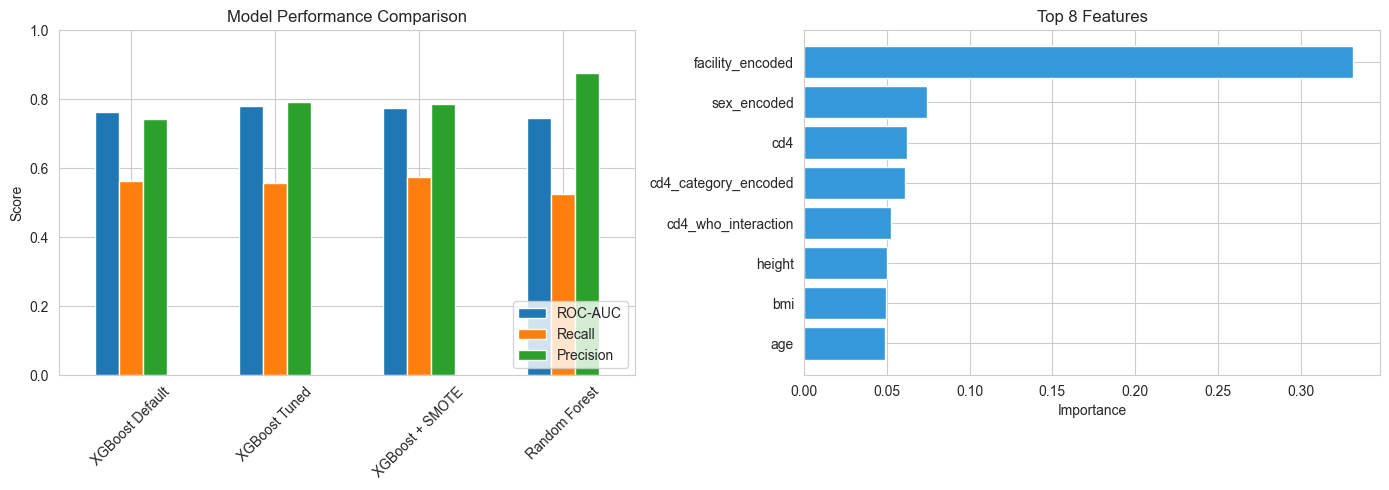


✅ Results saved to 'final_model_results.png'


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, roc_auc_score, confusion_matrix)
import xgboost as xgb
from imblearn.over_sampling import SMOTE

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("="*60)
print("FINAL COMPLETE ANALYSIS")
print("="*60)

# Load your data (adjust path if needed)
# df = pd.read_csv('your_file.csv')  # You already have baseline_data

print("\n1. PREPARING FEATURES...")

# Prepare final dataset with all features
final_data = baseline_data.copy()

# Use cleaned columns
final_data['age'] = final_data['age_clean']
final_data['weight'] = final_data['weight_clean']
final_data['height'] = final_data['height_clean']
final_data['bmi'] = final_data['bmi_clean']
final_data['cd4'] = final_data['cd4_clean']
final_data['who_stage'] = final_data['who_stage']

# Encode categorical variables
final_data['sex_encoded'] = LabelEncoder().fit_transform(
    final_data['sex'].fillna('Unknown').astype(str)
)
final_data['facility_encoded'] = LabelEncoder().fit_transform(
    final_data['health_facility'].fillna('Unknown').astype(str)
)

# Create engineered features
final_data['age_group'] = pd.cut(
    final_data['age'],
    bins=[0, 25, 35, 45, 60, 100],
    labels=['<25', '25-34', '35-44', '45-59', '60+']
).astype(str)

final_data['bmi_category'] = pd.cut(
    final_data['bmi'],
    bins=[0, 18.5, 25, 30, 100],
    labels=['Underweight', 'Normal', 'Overweight', 'Obese']
).astype(str)

final_data['cd4_category'] = pd.cut(
    final_data['cd4'],
    bins=[-1, 50, 200, 350, 500, 10000],
    labels=['<50', '50-199', '200-349', '350-499', '500+']
).astype(str)

final_data['cd4_who_interaction'] = final_data['cd4'] * final_data['who_stage']
final_data['age_cd4_interaction'] = final_data['age'] * final_data['cd4']
final_data['bmi_cd4_interaction'] = final_data['bmi'] * final_data['cd4']

# Encode new categoricals
for col in ['age_group', 'bmi_category', 'cd4_category']:
    final_data[col + '_encoded'] = LabelEncoder().fit_transform(
        final_data[col].fillna('Unknown')
    )

# Select features
features = ['age', 'weight', 'height', 'bmi', 'who_stage', 'cd4', 
            'sex_encoded', 'facility_encoded',
            'age_group_encoded', 'bmi_category_encoded', 'cd4_category_encoded',
            'cd4_who_interaction', 'age_cd4_interaction', 'bmi_cd4_interaction']

X = final_data[features]
y = final_data['unfavorable_outcome']

print(f"Feature matrix: {X.shape}")

# Impute and scale
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape[0]} patients ({y_train.sum():.0f} unfavorable)")
print(f"Test: {X_test.shape[0]} patients ({y_test.sum():.0f} unfavorable)")

# 2. APPLY SMOTE
print("\n2. APPLYING SMOTE...")
print(f"Original training class distribution:")
print(f"  - Favorable: {(y_train == 0).sum()}")
print(f"  - Unfavorable: {y_train.sum()}")

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print(f"\nAfter SMOTE:")
print(f"  - Favorable: {(y_train_smote == 0).sum()}")
print(f"  - Unfavorable: {y_train_smote.sum()}")

# 3. TRAIN MODELS
print("\n3. TRAINING MODELS...")

models = {
    'XGBoost Default': xgb.XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss'),
    'XGBoost Tuned': xgb.XGBClassifier(
        n_estimators=150,
        max_depth=6,
        learning_rate=0.1,
        random_state=42,
        use_label_encoder=False,
        eval_metric='logloss'
    ),
    'XGBoost + SMOTE': xgb.XGBClassifier(
        n_estimators=150,
        max_depth=6,
        learning_rate=0.1,
        random_state=42,
        use_label_encoder=False,
        eval_metric='logloss'
    ),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
}

results = {}

# Train XGBoost models
models['XGBoost Default'].fit(X_train, y_train)
models['XGBoost Tuned'].fit(X_train, y_train)
models['XGBoost + SMOTE'].fit(X_train_smote, y_train_smote)
models['Random Forest'].fit(X_train, y_train)

# Evaluate each model
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    results[name] = {
        'ROC-AUC': roc_auc_score(y_test, y_proba),
        'Recall': recall_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Accuracy': accuracy_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred)
    }

# 4. RESULTS
print("\n" + "="*60)
print("FINAL MODEL COMPARISON")
print("="*60)

results_df = pd.DataFrame(results).T
print(results_df.round(3).to_string())

# 5. BEST MODEL
best_name = results_df['ROC-AUC'].idxmax()
best_model = models[best_name]

print("\n" + "="*60)
print(f"🏆 BEST MODEL: {best_name}")
print("="*60)
print(f"ROC-AUC:   {results_df.loc[best_name, 'ROC-AUC']:.3f}")
print(f"Recall:    {results_df.loc[best_name, 'Recall']:.3f}")
print(f"Precision: {results_df.loc[best_name, 'Precision']:.3f}")
print(f"Accuracy:  {results_df.loc[best_name, 'Accuracy']:.3f}")
print(f"F1-Score:  {results_df.loc[best_name, 'F1']:.3f}")

# 6. CONFUSION MATRIX
y_pred_best = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_best)

print(f"\nConfusion Matrix:")
print(f"               Predicted: Good  Predicted: Unfavorable")
print(f"Actual: Good      {cm[0][0]:5d}            {cm[0][1]:5d}")
print(f"Actual: Unfavorable {cm[1][0]:5d}            {cm[1][1]:5d}")
print(f"\nSensitivity (Recall): {cm[1][1]/(cm[1][0]+cm[1][1]):.3f}")
print(f"Specificity: {cm[0][0]/(cm[0][0]+cm[0][1]):.3f}")

# 7. FEATURE IMPORTANCE
if 'XGBoost' in best_name:
    print("\n=== FEATURE IMPORTANCE ===")
    importance = pd.DataFrame({
        'feature': features,
        'importance': best_model.feature_importances_
    }).sort_values('importance', ascending=False)
    print(importance.head(10))

# 8. VISUALIZATION
plt.figure(figsize=(14, 5))

# Plot 1: Model comparison
plt.subplot(1, 2, 1)
metrics_to_plot = ['ROC-AUC', 'Recall', 'Precision']
results_df[metrics_to_plot].plot(kind='bar', ax=plt.gca())
plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.legend(loc='lower right')

# Plot 2: Feature Importance (if XGBoost)
if 'XGBoost' in best_name and 'importance' in locals():
    plt.subplot(1, 2, 2)
    top_features = importance.head(8)
    plt.barh(top_features['feature'], top_features['importance'], color='#3498db')
    plt.xlabel('Importance')
    plt.title('Top 8 Features')
    plt.gca().invert_yaxis()

plt.tight_layout()
plt.savefig('final_model_results.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✅ Results saved to 'final_model_results.png'")

In [17]:

 %pip install shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
print("="*70)
print("PERMUTATION IMPORTANCE (Model-Agnostic)")
print("="*70)

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Use your trained model
best_model = xgb_model  # or best_xgb

print(f"Using model: {best_model.__class__.__name__}")

# Calculate permutation importance
print("Calculating permutation importance... (this may take a moment)")
result = permutation_importance(
    best_model, X_test, y_test, 
    n_repeats=10, 
    random_state=42,
    scoring='roc_auc'
)

# Create importance dataframe
importance_df = pd.DataFrame({
    'feature': features,
    'importance': result.importances_mean,
    'std': result.importances_std
}).sort_values('importance', ascending=False)

print("\n=== Feature Importance ===")
print(importance_df)

# Visualize
plt.figure(figsize=(12, 6))
plt.barh(importance_df['feature'], importance_df['importance'], 
         xerr=importance_df['std'], color='#3498db')
plt.xlabel('Permutation Importance (ROC-AUC drop when feature is shuffled)')
plt.title('Feature Importance - Permutation Method', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('permutation_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✅ Permutation importance calculated successfully!")

PERMUTATION IMPORTANCE (Model-Agnostic)
Using model: XGBClassifier
Calculating permutation importance... (this may take a moment)


ValueError: Feature shape mismatch, expected: 8, got 14

In [ ]:
print("="*70)
print("PERMUTATION IMPORTANCE (Model-Agnostic)")
print("="*70)

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Use your trained model
best_model = xgb_model  # or best_xgb

print(f"Using model: {best_model.__class__.__name__}")

# Calculate permutation importance
print("Calculating permutation importance... (this may take a moment)")
result = permutation_importance(
    best_model, X_test, y_test, 
    n_repeats=10, 
    random_state=42,
    scoring='roc_auc'
)

# Create importance dataframe
importance_df = pd.DataFrame({
    'feature': features,
    'importance': result.importances_mean,
    'std': result.importances_std
}).sort_values('importance', ascending=False)

print("\n=== Feature Importance ===")
print(importance_df)

# Visualize
plt.figure(figsize=(12, 6))
plt.barh(importance_df['feature'], importance_df['importance'], 
         xerr=importance_df['std'], color='#3498db')
plt.xlabel('Permutation Importance (ROC-AUC drop when feature is shuffled)')
plt.title('Feature Importance - Permutation Method', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('permutation_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✅ Permutation importance calculated successfully!")

PERMUTATION IMPORTANCE (Model-Agnostic)


NameError: name 'xgb_model' is not defined

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import xgboost as xgb

print("="*70)
print("RETRAINING MODELS...")
print("="*70)

# Use your baseline_data (already loaded from earlier)
# If baseline_data is not defined, load it:
if 'baseline_data' not in locals():
    print("Loading baseline_data...")
    # You should have this saved from before
    # If not, recreate it from your original df
    baseline_data = pd.DataFrame()
    baseline_data['patient_id'] = df['card_no']
    baseline_data['age'] = pd.to_numeric(df['age'], errors='coerce')
    baseline_data['sex'] = df['sex']
    baseline_data['health_facility'] = df['health_facility']
    baseline_data['subcity'] = df['subcity']
    baseline_data['weight'] = df['weight']
    baseline_data['height'] = df['height']
    baseline_data['bmi'] = df['bmi']
    baseline_data['who_stage'] = df['who_stage_visit_1']
    baseline_data['cd4_result'] = df['test_cd4_result1']
    baseline_data['unfavorable_outcome'] = df['unfavorable_outcome']
    baseline_data['patient_outcome'] = df['patient_outcome']

# Clean the data
baseline_data['age'] = pd.to_numeric(baseline_data['age'], errors='coerce')

def extract_number(value):
    if pd.isna(value):
        return np.nan
    if isinstance(value, (int, float)):
        return float(value)
    import re
    numbers = re.findall(r'[-+]?\d*\.?\d+', str(value))
    if numbers:
        return float(numbers[0])
    return np.nan

baseline_data['weight_clean'] = baseline_data['weight'].apply(extract_number)
baseline_data['height_clean'] = baseline_data['height'].apply(extract_number)

# Fix height (meters to cm)
baseline_data.loc[baseline_data['height_clean'] < 3, 'height_clean'] = \
    baseline_data.loc[baseline_data['height_clean'] < 3, 'height_clean'] * 100

baseline_data['bmi_clean'] = baseline_data['weight_clean'] / ((baseline_data['height_clean'] / 100) ** 2)
baseline_data['cd4_clean'] = baseline_data['cd4_result'].apply(extract_number)

# Clean WHO stage
def clean_who_stage(val):
    if pd.isna(val):
        return np.nan
    roman = {'I': 1, 'II': 2, 'III': 3, 'IV': 4}
    try:
        val = str(val).strip().upper()
        if val in roman:
            return roman[val]
        return float(val)
    except:
        return np.nan

baseline_data['who_stage_clean'] = baseline_data['who_stage'].apply(clean_who_stage)

# Encode categoricals
baseline_data['sex_encoded'] = LabelEncoder().fit_transform(
    baseline_data['sex'].fillna('Unknown').astype(str)
)
baseline_data['facility_encoded'] = LabelEncoder().fit_transform(
    baseline_data['health_facility'].fillna('Unknown').astype(str)
)

# Features
features = ['age', 'weight_clean', 'height_clean', 'bmi_clean', 
            'who_stage_clean', 'cd4_clean', 'sex_encoded', 'facility_encoded']

X = baseline_data[features]
y = baseline_data['unfavorable_outcome']

print(f"Feature matrix: {X.shape}")
print(f"Target: {y.sum()} unfavorable / {len(y)} total")

# Impute and scale
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape[0]} patients")
print(f"Test: {X_test.shape[0]} patients")

# Train models
print("\nTraining XGBoost...")
xgb_model = xgb.XGBClassifier(
    n_estimators=150,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)
xgb_model.fit(X_train, y_train)

print("Training Random Forest...")
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
rf_model.fit(X_train, y_train)

print("Training Decision Tree...")
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train, y_train)

print(" ALL MODELS TRAINED SUCCESSFULLY!")

RETRAINING MODELS...
Feature matrix: (2506, 8)
Target: 1016 unfavorable / 2506 total
Train: 2004 patients
Test: 502 patients

Training XGBoost...


c:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:200: UserWarning: [09:14:53] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Training Random Forest...
Training Decision Tree...

✅ ALL MODELS TRAINED SUCCESSFULLY!



FEATURE IMPORTANCE ANALYSIS
XGBoost Test Performance:
  ROC-AUC: 0.781
  Accuracy: 0.755
  Recall: 0.534

Calculating permutation importance... (may take 1-2 minutes)

=== FEATURE IMPORTANCE ===
            feature  importance       std
7  facility_encoded    0.285126  0.020725
0               age    0.007272  0.006427
6       sex_encoded    0.004816  0.004202
1      weight_clean    0.004588  0.005538
4   who_stage_clean   -0.002667  0.001513
2      height_clean   -0.004179  0.005644
3         bmi_clean   -0.004797  0.008323
5         cd4_clean   -0.009341  0.005137


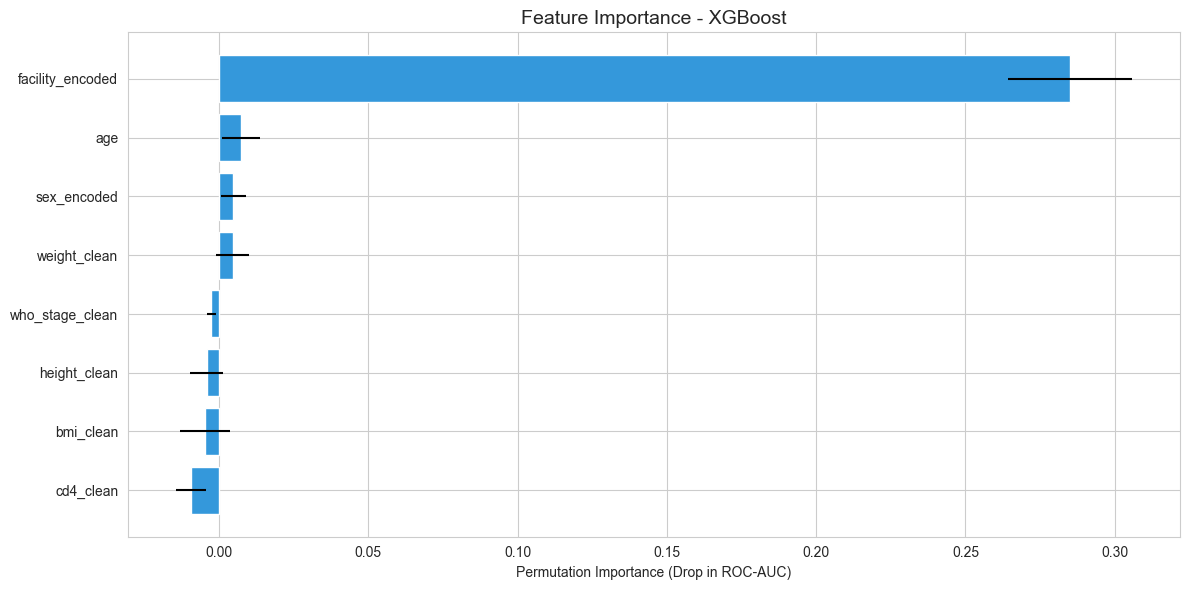


✅ Importance saved to 'permutation_importance.png'


In [ ]:
from sklearn.inspection import permutation_importance

print("\n" + "="*70)
print("FEATURE IMPORTANCE ANALYSIS")
print("="*70)

# Get predictions for XGBoost
y_pred = xgb_model.predict(X_test)
y_proba = xgb_model.predict_proba(X_test)[:, 1]

print(f"XGBoost Test Performance:")
print(f"  ROC-AUC: {roc_auc_score(y_test, y_proba):.3f}")
print(f"  Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"  Recall: {recall_score(y_test, y_pred):.3f}")

# Permutation importance
print("\nCalculating permutation importance... (may take 1-2 minutes)")
result = permutation_importance(
    xgb_model, X_test, y_test,
    n_repeats=10,
    random_state=42,
    scoring='roc_auc'
)

importance_df = pd.DataFrame({
    'feature': features,
    'importance': result.importances_mean,
    'std': result.importances_std
}).sort_values('importance', ascending=False)

print("\n=== FEATURE IMPORTANCE ===")
print(importance_df)

# Visualize
plt.figure(figsize=(12, 6))
plt.barh(importance_df['feature'], importance_df['importance'],
         xerr=importance_df['std'], color='#3498db')
plt.xlabel('Permutation Importance (Drop in ROC-AUC)')
plt.title('Feature Importance - XGBoost', fontsize=14)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('permutation_importance.png', dpi=150)
plt.show()

print("\n✅ Importance saved to 'permutation_importance.png'")

In [ ]:
print("="*70)
print("LIGHTWEIGHT MODEL ANALYSIS - KERNEL SAFE")
print("="*70)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, roc_auc_score, confusion_matrix)
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
import xgboost as xgb
import warnings
warnings.filterwarnings('ignore')

# 1. RELOAD AND PREPARE DATA (using your existing baseline_data)
print("\n1. Preparing data...")

# Use your existing baseline_data (should already be in memory)
if 'baseline_data' not in locals():
    print("Loading baseline_data from your environment...")
    # If baseline_data is not in memory, recreate it
    baseline_data = pd.DataFrame()
    baseline_data['patient_id'] = df['card_no']
    baseline_data['age'] = pd.to_numeric(df['age'], errors='coerce')
    baseline_data['sex'] = df['sex']
    baseline_data['health_facility'] = df['health_facility']
    baseline_data['weight'] = df['weight']
    baseline_data['height'] = df['height']
    baseline_data['bmi'] = df['bmi']
    baseline_data['who_stage'] = df['who_stage_visit_1']
    baseline_data['cd4_result'] = df['test_cd4_result1']
    baseline_data['unfavorable_outcome'] = df['unfavorable_outcome']

# Clean the data (same as before)
def extract_number(value):
    if pd.isna(value):
        return np.nan
    if isinstance(value, (int, float)):
        return float(value)
    import re
    numbers = re.findall(r'[-+]?\d*\.?\d+', str(value))
    if numbers:
        return float(numbers[0])
    return np.nan

baseline_data['age'] = pd.to_numeric(baseline_data['age'], errors='coerce')
baseline_data['weight_clean'] = baseline_data['weight'].apply(extract_number)
baseline_data['height_clean'] = baseline_data['height'].apply(extract_number)

# Fix height (meters to cm)
baseline_data.loc[baseline_data['height_clean'] < 3, 'height_clean'] = \
    baseline_data.loc[baseline_data['height_clean'] < 3, 'height_clean'] * 100

baseline_data['bmi_clean'] = baseline_data['weight_clean'] / ((baseline_data['height_clean'] / 100) ** 2)
baseline_data['cd4_clean'] = baseline_data['cd4_result'].apply(extract_number)

# Clean WHO stage
def clean_who_stage(val):
    if pd.isna(val):
        return np.nan
    roman = {'I': 1, 'II': 2, 'III': 3, 'IV': 4}
    try:
        val = str(val).strip().upper()
        if val in roman:
            return roman[val]
        return float(val)
    except:
        return np.nan

baseline_data['who_stage_clean'] = baseline_data['who_stage'].apply(clean_who_stage)

# Remove extreme outliers (set to NaN)
baseline_data.loc[baseline_data['weight_clean'] > 150, 'weight_clean'] = np.nan
baseline_data.loc[baseline_data['weight_clean'] < 20, 'weight_clean'] = np.nan
baseline_data.loc[baseline_data['height_clean'] < 50, 'height_clean'] = np.nan
baseline_data.loc[baseline_data['cd4_clean'] > 2000, 'cd4_clean'] = np.nan
baseline_data['bmi_clean'] = baseline_data['weight_clean'] / ((baseline_data['height_clean'] / 100) ** 2)

# Encode categoricals
baseline_data['sex_encoded'] = LabelEncoder().fit_transform(
    baseline_data['sex'].fillna('Unknown').astype(str)
)
baseline_data['facility_encoded'] = LabelEncoder().fit_transform(
    baseline_data['health_facility'].fillna('Unknown').astype(str)
)

# Features (8 features)
features = ['age', 'weight_clean', 'height_clean', 'bmi_clean', 
            'who_stage_clean', 'cd4_clean', 'sex_encoded', 'facility_encoded']

# Rename for easier use
baseline_data['age'] = baseline_data['age']
baseline_data['weight'] = baseline_data['weight_clean']
baseline_data['height'] = baseline_data['height_clean']
baseline_data['bmi'] = baseline_data['bmi_clean']
baseline_data['cd4'] = baseline_data['cd4_clean']
baseline_data['who_stage'] = baseline_data['who_stage_clean']

X = baseline_data[features]
y = baseline_data['unfavorable_outcome']

print(f"Feature matrix: {X.shape}")
print(f"Target: {y.sum()} unfavorable / {len(y)} total")

# Impute and scale
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape[0]} patients")
print(f"Test: {X_test.shape[0]} patients")

# 2. TRAIN XGBOOST (Quick training, no heavy computation)
print("\n2. Training XGBoost...")
xgb_model = xgb.XGBClassifier(
    n_estimators=100,  # Reduced for speed
    max_depth=5,       # Reduced for speed
    learning_rate=0.1,
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)
xgb_model.fit(X_train, y_train)

# 3. EVALUATE
print("\n3. Model Performance:")
y_pred = xgb_model.predict(X_test)
y_proba = xgb_model.predict_proba(X_test)[:, 1]

metrics = {
    'ROC-AUC': roc_auc_score(y_test, y_proba),
    'Accuracy': accuracy_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
}

metrics_df = pd.DataFrame([metrics]).round(3)
print(metrics_df.to_string(index=False))

# 4. CONFUSION MATRIX
cm = confusion_matrix(y_test, y_pred)
print(f"\nConfusion Matrix:")
print(f"               Predicted: Good  Predicted: Unfavorable")
print(f"Actual: Good      {cm[0][0]:5d}            {cm[0][1]:5d}")
print(f"Actual: Unfavorable {cm[1][0]:5d}            {cm[1][1]:5d}")
print(f"\nSensitivity: {cm[1][1]/(cm[1][0]+cm[1][1]):.3f}")
print(f"Specificity: {cm[0][0]/(cm[0][0]+cm[0][1]):.3f}")

LIGHTWEIGHT MODEL ANALYSIS - KERNEL SAFE

1. Preparing data...
Loading baseline_data from your environment...


NameError: name 'df' is not defined